## 1.2 Probability Theory

### Laws
$$
\begin{align*}
& \text{Sum Rule: } p(x_i) = \sum_j p(x_i, y_j) \\
& \text{Product Rule: } p(x_i, y_j) = p(x_i | y_j)p(y_j) \\
& \text{Total Probability: } p(x_i) = \sum_j p(x_i | y_j)p(y_j) \\
\end{align*}
$$

Note that the law of total probability simply combines the product and sum rules. These laws may be extended to an arbitrary number of random variables.

### Densities

Probability Density $p(x)$ for a continuous RV $x$ gives probability: $$p(x \in (a, b)) = \int_a^b p(x) dx$$
Where $p(x) \ge 0$ and $\int_{-\infty}^\infty p(x)dx = 1$

Now, assume $x = g(y)$ where $x$ and $y$ are both continuous RVs. Then:
$$p_y(y) = p_x(x) \bigg|\frac{dx}{dy}\bigg| = p_x(g(y))\big|g'(y)\big|$$
Intuition:\
Consider an arbitrarily small interval $(y, \ y + \delta y)$. The corresponding interval for $x$ is $(x, \ x + \delta x)$ with $\delta x \approx g'(y)\delta y$ (chain rule).

Consider CDFs:
- Increasing $g$ (i.e. $g'(y) > 0$): $$F_y(y) = P(Y\le y) = P(X \le g(y)) = F_x(g(y))$$
Then, differentiating w.r.t. $y$ yields the PMF of $x$ (by the chain rule): $$F_x(g(y))\frac{d}{dy} = p_x(g(y))g'(y)$$
- Decreasing $g$ (i.e. $g'(y) < 0$): $$Y \le y \iff g(Y) \ge g(y) \iff X \ge x \\ F_y(y) = P(Y\le y) = P(X \ge x) = 1 - F_x(x)$$
Then, differentiating w.r.t. $y$ yields the PMF of $x$ (by the chain rule): $$F_x(g(y))\frac{d}{dy} = -p_x(g(y))g'(y)$$

Key intuition is that densities are probability **per unit length** of the RV. Transformation like $g(y)$ **don't** increase/decrease probability mass, they simply spread or condense it over different intervals of the support $x$. This should seem natural since total probability is always conserved by the law that $\int_{-\infty}^\infty p(x)dx = 1$\
The term $\big| g'(y)\big|$ is the factor governing the expansion/contraction.

**Core Idea:** *Probability* is invariant under reparameterization, but *density* is not.

**Key Consequence**: The *maximum* of a probability density is dependent on *the choice of variable*.

## 1.2.3 Bayesian Probabilities

Let $\mathcal D = {t_1, ..., t_N}$ denote oure observed data. A data-generating PMF for the observed data may be denoted $p(\mathcal D| \bf w)$. By Baye's Theorem, we may then express the probability of observing the parameters $\bf w$ conditional on the observed data as: $$p(\mathbf w | \mathcal D) = \frac{p(\mathcal D | \mathbf w) p(\mathbf w)}{p(\mathcal D)}$$
In a sense, this is the probability that the model parameters $\bf w$ are the "*true*" parameters (i.e. those of the true DGP) given the observed data. In the Bayesian vernacular we'd say: $$\text{posterior } \propto \text{likelihood } \times \text{ prior}$$
Where the denominator $p(\mathcal D) \coloneqq \text{ evidence}$ is dropped because it is typically unknown and is not necessary for estimation. It is treated as a constant that simply normalizes the numerator, which is called the ***likelihood function***, so that it is bounded by $[0, 1]$.\
Note that the evidence may be expressed (by the law of total probability) as: $$p(\mathcal D) = \int p(\mathcal D|\mathbf w)p(\mathbf w) d\bf w$$

**The Bayesian Perspective**\
From a Bayesian POV, the problem of selecting parameters treats the data as an absolute. There is **only one** possible dataset, that which is observed: $\mathcal D$. The uncertainty is about which parameters $\bf w$ are the parameters that *generated* that data. So, the probability distributions are drawn over $\bf w$, not over $\mathcal D$.

In MLE, we select $\bf w$ to *maximize* the likelihood PMF $p(\mathcal D | \bf w)$ - this is a *frequentist approach*.

## 1.2.4 Multi-Variate Gaussian

Univariate Gaussian: $$ \mathcal{N}(x|\mu, \sigma^2) = (2\pi\sigma)^{-1/2} \exp \bigg[-\frac{1}{2\sigma^2}(x - \mu)^2\bigg]$$
Multivariate Gaussian: $$ \mathcal{N}(\mathbf{x|\mu, \Sigma}) = \frac{(2\pi)^{-D/2}}{\big|\mathbf{\Sigma}\big|^{1/2}}\exp \bigg[-\frac{1}{2}(\mathbf x - \mathbf \mu)^\intercal \mathbf \Sigma^{-1} (\mathbf x - \mathbf \mu)\bigg]$$
Where $D$ is the *number* of dimensions in the span of $\bf \mu$

The book often replaces the variance with the ***precision***, which is simply the inverse variance. Denoted:
$$\beta^{-1} \coloneqq \sigma^2$$

## 1.2.6 Bayesian Curve Fitting

#### Maximum a-Posteriori (MAP) Estimation

MAP estimation is analogous to MLE but adds the incorporation of prior information; typically by specifying a conditional distribution of the parameters $\bf w$ as the prior.

A Gaussian example: 
$$
\begin{align*}
& \text{Likelihood: } \ p(\mathbf t | \mathbf w, \beta) = \prod_n \mathcal{N} (t_n | y(x_n, \mathbf w), \beta^{-1}) \\
& \text{Prior: } \ \ \ \ \ \ \ \ \ \  p(\mathbf w, \alpha) = \mathcal N(\mathbf w| \mathbf 0, \alpha^{-1}\mathbf I) = \big(\frac{\alpha}{2\pi}\big)^{M / 2}\exp\bigg[-\frac{\alpha}{2}\mathbf w ^ \intercal \mathbf w\bigg] \\

& \implies \text{Posterior: } \ \ p(\mathbf{w}|\mathbf{x, t}, \alpha, \beta) \propto p(\mathbf{t, x, w}, \beta)p(\mathbf w| \alpha)
\end{align*}
$$
Where $\alpha$ is the precision of the distribution of parameters and $M$ is the total number of parameters in $\bf w$.

Selecting $\bf w$ under MAP is similar to MLE. We simply take the negative log of the posterior and select $\bf w$ to maximize. If we wrote this out, we'd find it equal to the minimum of: $$\frac{\beta}{2}\sum_n {y(x_n, \mathbf w) - t_n}^2 + \frac{\alpha}{2}\mathbf w^\intercal \mathbf w$$
Which is equivalent to minimizing the regularized sum-of-squares error function with a regularization parameter $\lambda = \alpha / \beta$

**Posterior Predictive Distribution**\
We may express the probability of observing a response value $t$ given observation $x$ and data $\bf x, t$ as:
$$p(t|x, \ \mathbf x, \mathbf t) = \int p(t|x, \mathbf w)p(\mathbf w|\mathbf x, \mathbf t) d\bf w$$
Here $p(\mathbf w|\mathbf x, \mathbf t)$ is the **posterior distribution** over the parameters, and $p(t|x, \mathbf w)$ is the **likelihood** (aka. *sampling distribution*).

When the likelihood and prior are both Gaussian (or any pair of conjugate distributions), then the posterior is also Gaussian:
$$p(t|x, \mathbf x, \mathbf t) = \mathcal N (t|m(x), s^2(x))$$

Let $\boldsymbol\Phi \in \mathbb R^{N\times M}$ be the **design matrix**, whose $n$-th row is $\phi(x_n)^\intercal$, and let $\mathbf t \in \mathbb R^N$ be the targets. Then:
$$\mathbf S^{-1} = \alpha \mathbf I_M + \beta\,\boldsymbol\Phi^\intercal\boldsymbol\Phi \ \in \mathbb R^{M\times M} \qquad\Big(\text{equiv. } \alpha\mathbf I + \beta\textstyle\sum_n \phi(x_n)\phi(x_n)^\intercal\Big)$$

Define the posterior mean **weight vector** — this is implicit but unnamed in Bishop's $m(x)$ formula:
$$\mathbf m_N \coloneqq \beta\,\mathbf S\,\boldsymbol\Phi^\intercal\mathbf t \ \in \mathbb R^M \qquad\Big(\text{equiv. } \beta\mathbf S\textstyle\sum_n \phi(x_n)t_n\Big)$$

For a single query point $x$, the posterior predictive mean and variance are then just:
$$m(x) = \phi(x)^\intercal \mathbf m_N \qquad\qquad s^2(x) = \beta^{-1} + \phi(x)^\intercal \mathbf S \phi(x)$$

**Vectorized form.** Evaluating at a batch of query points with design matrix $\boldsymbol\Phi_\ast \in \mathbb R^{N_\ast\times M}$ (e.g. $\boldsymbol\Phi_\ast = \boldsymbol\Phi$, to evaluate at the training points themselves):
$$\mathbf m = \boldsymbol\Phi_\ast \mathbf m_N = \beta\,\boldsymbol\Phi_\ast \mathbf S \boldsymbol\Phi^\intercal \mathbf t \ \in \mathbb R^{N_\ast}$$
$$\mathbf s^2 = \beta^{-1}\mathbf 1 + \operatorname{diag}\big(\boldsymbol\Phi_\ast \mathbf S \boldsymbol\Phi_\ast^\intercal\big) \ \in \mathbb R^{N_\ast}$$

**NOTE:** $\beta\,\boldsymbol\Phi \mathbf S \boldsymbol\Phi^\intercal$ is exactly the ridge/generalized Hat matrix $\mathbf H_\lambda$ ($\lambda = \alpha/\beta$): $\mathbf m$ (evaluated in-sample) is a linear shrinkage of $\mathbf t$, not a hard projection.

### Clearing Some Things Up

We have a prior and a likelihood that are both Gaussian. The posterior is therefore also Gaussian. Thus, we know that the posterior will have the form:
$$p(\mathbf w | \mathcal D) = \mathcal N (\mathbf w | \mathbf m_N, \mathbf S)$$
Where, $\mathbf m_N$ is the vector of **mean weights** (i.e. the expected value of each weight coefficient).\
And $\mathbf S$ is the posterior covariance matrix of the weights.

Thus with $M$ weights, $\mathbf m_N$ is $[M, 1]$ and $\bf S$ is $[M, M]$.

With our data, this posterior is proportional to: $$ p(\mathbf w | \mathbf t, \mathbf x) \propto p(\mathbf t | \mathbf x, \mathbf w) p(\mathbf w)$$

$$
\begin {align*}
& \text{Prior: } \ \ \ \ \ \ \ \ \ \  p(\mathbf w, \alpha) = \mathcal N(\mathbf w| \mathbf 0, \alpha^{-1}\mathbf I) = \big(\frac{\alpha}{2\pi}\big)^{M / 2}\exp\bigg[-\frac{\alpha}{2}\mathbf w ^ \intercal \mathbf w \bigg] \\
& \text{Likelihood: } \ \ p(\mathbf t| \mathbf x, \mathbf w) = \mathcal{N} (\mathbf t | \mathbf \Phi \mathbf w, \ \beta^{-1} \mathbf I)
\end{align*}
$$

#### Solving
We can solve in log-space more conveniently: $$\ln p(\mathbf w | \mathbf t, \mathbf x) \propto \ln p(\mathbf t| \mathbf{x, w}) + \ln p(\mathbf w)$$
Expanding (and dropping terms from the Gaussian PDFs that don't depend on $\bf w$): 
$$
\begin{align*}
& \ln p(\mathbf w | \mathbf t, \mathbf x) \propto - \frac{\beta}{2} (\mathbf t - \mathbf{\Phi w})^\intercal (\mathbf t - \mathbf{\Phi w}) - \frac{\alpha}{2} \mathbf w ^\intercal \mathbf w \\
& \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \propto -\frac{1}{2} (\mathbf w - \mathbf m_N)^\intercal \mathbf S^{-1}(\mathbf w - \mathbf m_N)
\end{align*}
$$
With, $$\mathbf m_N \coloneqq \beta\,\mathbf S\,\boldsymbol\Phi^\intercal\mathbf t \ \in \mathbb R^M \\ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \mathbf S^{-1} = \alpha \mathbf I_M + \beta\,\boldsymbol\Phi^\intercal\boldsymbol\Phi \ \in \mathbb R^{M\times M}$$

So, we have our **Posterior**: $p(\mathbf w | \mathbf t, \mathbf x) = \mathcal N(\mathbf w| \mathbf m_n, \mathbf S)$\
What about the **posterior predictive distribution**?

The posterior predictive distribution evaulates the probability of observing a specific target $t$ given a specific input observation $x$ by averaging over the posterior distribution. In other words, it it the ***Expectation*** of the *likelihood* taken over the *posterior*:
$$p(t|x, \ \mathbf x, \mathbf t) = \int p(t|x, \mathbf w)p(\mathbf w|\mathbf x, \mathbf t) d\bf w$$

**NOTE:** The *likelihood* here is for a specific observation $x$, not the full input dataset. So, its PDF is: $$p(t|x, \mathbf w) = \mathcal N (t | \phi(x)^\intercal \mathbf w, \beta^{-1})$$

The prior and pointwise-likelihood are both Gaussians. The product of Gaussians is a Gaussian. The sum of Gaussians is a Gaussian. And the integral is a sum of infinitesimals, so it is *also Gaussian*. We end up with:
$$p(t|x, \mathbf x, \mathbf t) = \mathcal N(t|m(x), s^2(x)) \\ 
\ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ = \mathcal N (t|\phi(x)^\intercal \mathbf m_N, \ \beta^{-1} + \phi(x)^\intercal \mathbf S \phi(x))$$

### Demo

Once we have the posterior predictive distribution, predicting an observation $t_i$ simply corresponds to drawing the expected value of the posterior predictive distribution at that point: $$\hat{t}_i = \phi(x_i)^\intercal \mathbf m_N$$
With full predictive uncertainty given by $t_i \sim \mathcal N (\hat{t}_i, s^2(x_i))$.

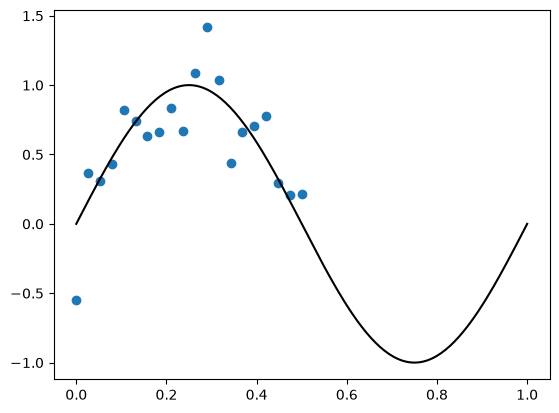

In [43]:
import numpy as np
from matplotlib import pyplot as plt

rng = np.random.default_rng()

s = 0.2  # precision

x = np.linspace(0, 0.5, 20)
t = np.sin(2 * np.pi *x) + rng.normal(0, s, size=x.shape)

x_full = np.linspace(0, 1, 200)
t_full = np.sin(2 * np.pi * x_full)

plt.scatter(x, t)
plt.plot(x_full, t_full, color='black')
plt.show()

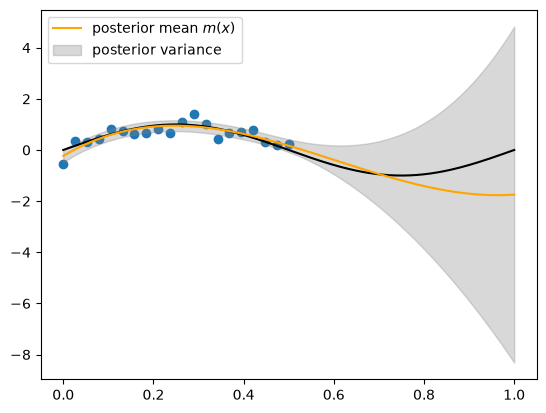

In [ ]:
alpha = 0
beta = s**(-2)

# design matrix: Phi.shape == (N, M), row n is phi(x_n)^T
Phi = np.vstack([np.ones_like(x), x, x**2, x**3]).T

# S^{-1} = alpha*I + beta * Phi^T @ Phi   -> (M, M)
S = np.linalg.inv(alpha * np.eye(Phi.shape[1]) + beta * Phi.T @ Phi)

# posterior mean weight vector: m_N = beta * S @ Phi^T @ t   -> (M,)
m_N = beta * S @ Phi.T @ t

# posterior mean at the training points: m(x_n) = phi(x_n)^T @ m_N, vectorized as Phi @ m_N
m_x = Phi @ m_N   # (N,)

# posterior variance at each training point: s^2(x_n) = 1/beta + phi(x_n)^T @ S @ phi(x_n)
s2 = 1/beta + np.diag(Phi @ S @ Phi.T)   # (N,)


# design matrix for full input range
Phi_full = np.vstack([np.ones_like(x_full), x_full, x_full**2, x_full**3]).T

# posterior mean and variance for full input range
m_x_full = Phi_full @ m_N
s2_full = 1/beta + np.diag(Phi_full @ S @ Phi_full.T)   # (N,)

# plt.errorbar(x, t, yerr=np.sqrt(s2), fmt='o', alpha=0.6, label='data')
plt.scatter(x, t)
plt.plot(x_full, t_full, color='black')
plt.plot(x_full, m_x_full, color='orange', label='posterior mean $m(x)$')
plt.fill_between(x_full, m_x_full - np.sqrt(s2_full), m_x_full + np.sqrt(s2_full), color='gray', alpha=0.3, label='posterior variance')


plt.legend()
plt.show()

In [ ]:
# lets modularize to see the effects of different parameters and training data set sizes

def generate_data(sigma, N, seed: int | None = None):
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 0.5, N)
    t = np.sin(2 * np.pi * x) + rng.normal(0, sigma, size=x.shape)
    return x, t

class GaussianProcess:
    def __init__(self, alpha, beta, x_tr, t_tr):
        self.alpha = alpha
        self.beta = beta
        self.x_tr = x_tr
        self.t = t_tr
        self.Phi = np.vander(x_tr, N=4, increasing=True)  # example with polynomial features of order 3
        self.m_N = None
        self.S = None

    def fit(self):
        self.S = np.linalg.inv(self.alpha * np.eye(self.Phi.shape[1]) + self.beta * self.Phi.T @ self.Phi)
        self.m_N = self.beta * self.S @ self.Phi.T @ self.t

    def predict(self, Phi_full):
        m_x = Phi_full @ self.m_N
        s2 = 1/self.beta + np.diag(Phi_full @ self.S @ Phi_full.T)
        self.m_x, self.s2 = m_x, s2
        self.preds , self.squared_std_err = m_x, s2  # alias

    def update(self, x_new, t_new):
        self.x_tr = np.hstack([self.x_tr, x_new])
        self.Phi = np.vander(self.x_tr, N=4, increasing=True)  # example with polynomial features of order 3
        self.t = np.hstack([self.t, t_new])
        self.fit()  # refit with updated design matrix and targets

def plot_gp(gp, x_full, Phi_full=None):
    if Phi_full is None:
        Phi_full = np.vander(x_full, N=gp.Phi.shape[1], increasing=True)  # create design matrix as polynomial features (order N)
    gp.predict(Phi_full)

    plt.plot(x_full, t_full, label="True Process")
    plt.scatter(gp.x_tr, gp.t, c='b', s=50, zorder=10, label='Training Data')
    
    plt.plot(x_full, gp.m_x, c='orange', label='Prediction')
    plt.fill_between(x_full, gp.m_x - np.sqrt(gp.s2), gp.m_x + np.sqrt(gp.s2), color='lightgray', label="Credible Interval")

    plt.legend()
    plt.show()

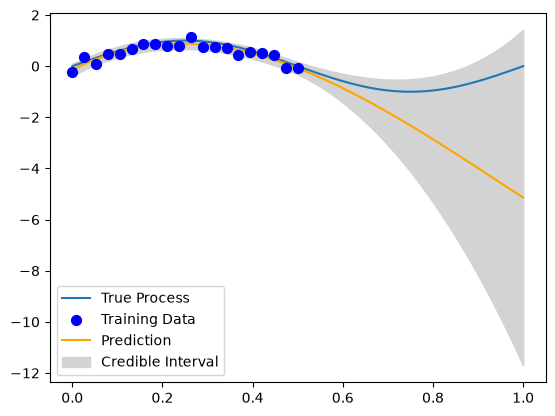

In [110]:
sigma = 0.2

x_tr, t_tr = generate_data(sigma=sigma, N=20)

x_full = np.linspace(0, 1, 200)
Phi_full = np.vander(x_full, N=4, increasing=True)  # example with polynomial features of order 3

gp = GaussianProcess(alpha=0, beta=1/sigma**2, x_tr=x_tr, t_tr=t_tr)
gp.fit()
gp.predict(Phi_full)

plot_gp(gp, x_full, Phi_full=Phi_full)

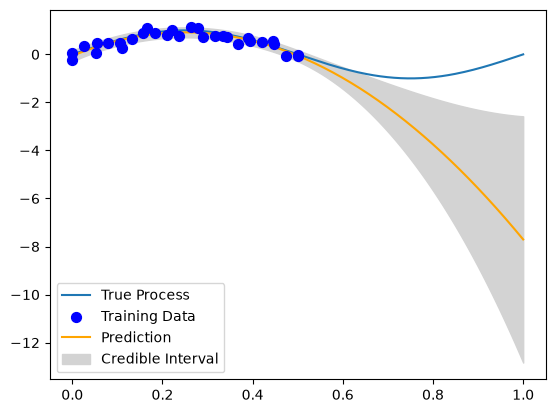

In [111]:
gp.update(*generate_data(sigma=sigma, N=10))
gp.predict(Phi_full)
plot_gp(gp, x_full, Phi_full=Phi_full)

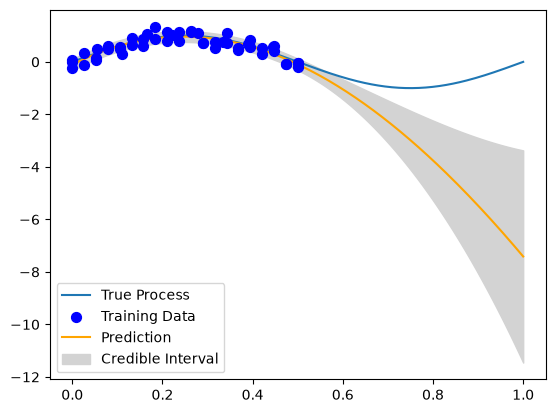

In [112]:
gp.update(*generate_data(sigma=sigma, N=20))
gp.predict(Phi_full)
plot_gp(gp, x_full, Phi_full=Phi_full)

Get's increasingly confident - how to regularize further to counteract overconfidence? Tuning $\alpha$ or $\beta$ won't help. The error is *epistemic*. Adding data will increase confidence down to the floor of `sigma` regardless of initial uncertainty. Raising $\alpha$ actaully increases $\bf S$ anyways. The cubic polynomial does not fit outside of the training data regime. Need a better framework to generalize.......

# 1.5 Decision Theory

How do we make optimal decisions under uncertainty? What is the appropriate action to take given the results of inference?

### 1.5.1 Minimizing Misclassification Rate

One approach is to minimize the number of misclassifications (in a classification context).\
Suppose we assign each value of $\bf x$ to a class by dividing the input space into ***decision regions*** $R_k$ corresponding to classes $C_k$. The borders of these regions are ***decision boundaries***.

In general, then, the probability of **misclassification** is: 
$$p(\text{mistake}) = \sum_k p(\mathbf x \in R_k, C_j) = \sum_k \int_{R_k}p(\mathbf x, C_j) d\mathbf x, \ \ \ \forall j \ne k$$
And the probability of **correct** classification is:
$$p(\text{correct}) = \sum_k p(\mathbf x \in R_k, C_k) = \sum_k \int_{R_k}p(\mathbf x, C_k) d\mathbf x \\
\implies p(\text{mistake}) = 1 - p(\text{correct})$$

We can maximize the probability of correct classification (and thus minimize misclassification) by defining decision regions such that $\bf x$ is assigned to the class for which $p(\mathbf x, C_k)$ is *largest*. This is where the *posterior probability* $p(C_k | \bf x)$ is largest (by the product rule).

### 1.5.2 Minimizing Expected Loss

We can generalize the optimal decision rule using loss functions, which enable us (among many other things) to adjust penalties for differet types of errors. Such as penalizing **Type 2 Errors** (false negatives) more than **Type 1 Errors** (false positives).

### 1.5.4 Inference and Decision

The text defines the ***Inference Stage*** as the stage in which we learn to model a posterior distribution $p(C_k|\bf x)$ given training data and the ***Decision Stage*** as the stage in which we use the posterior distribution to make decisions. It defines a function that combines the two stages by mapping the inputs $\bf x$ directly into decisions as a ***Discriminant Function***.

#### Three Approaches to Solving Decision Problems

1. Solve the class conditional densities $p(\mathbf x| C_k)$ individually for all $k$ and infer prior class probabilities $p(C_k)$. Then use Bayes' theorem: $$p(C_k | \mathbf x) = \frac{p(\mathbf x | C_k) p(C_k)}{p(\mathbf x)}$$
Then determine class memberships for each new input $\bf x$, choose the corresponding $C_k$ by computing the maximum posterior probability $p(C_k | \mathbf x)$. Such approaches, that implicitly or explicitly model distributions of *both* inputs *and* outputs are called ***Generative Models*** - because they can generate synthetic data points within the input space.




2. Solve the inference problem of determining $p(C_k | \bf x)$ directly. Such approaches that model the posterior distributions directly are called ***Discriminative Models***.

3. Learn or define a function $f(\bf x)$, called a *discriminant function*, that maps $\mathbf x \mapsto C_k$. In such cases, probability plays **no role**.

The first approach is the most demanding since we must find the joint distribution over both $\bf x$ and $C_k$. The second approach only requires posterior probabilities $p(C_k | \bf x)$, which are typically much easier to define. 

# 1.6 Information Theory

Information quantity is considered to be represented by $h(x)$ which is a *monotonic function* of the probability $p(x)$. It is axiomatically defined as: $$h(x) = -\log p(x)$$
**NOTE:** This definition posesses *additivity* for unrelated (i.e. independent) events: $$p(x, y) = p(x)p(y) \implies h(x, y) = h(x) + h(y)$$
- The information gained by observing two *unrelated* events is equal to the sum of the information gained by observing both independently

**NOTE:** Typically we use $\log_2$, defining each unit of information $h(x)$ as a ***bit***. However, other bases work in principle. When $\ln$ is used each unit is called a ***nat*** (for natural log).\
The book prefers *nats* to *bits*.

***Entropy:***\
The *average* amount of information in a message (or dataset $X$) is the *entropy* defined as the expectation of the information $h(x)$ taken over the distribution of $x$:
$$H[x] = -\sum_x p(x) \log p(x)$$

Usefully of course, a bit can be expressed as a Boolean. Thus, we can express the number of bits required to convey a message (or to determine the *state* of a random variable $X$) using its entropy. In fact, the entropy of a random variable (or random process more generally) **is the average amount of information** (expressed in Boolean bits, or nats, or whatever) needed to **specify its state**.

The entropy of $x$ thus depends on the distribution of $x$. Some distributions have higher entropy than others. For instance, if $x$ is discrete and highly skewed, then we could express higher probability states of $x$ using fewer bits (i.e. shorter codes like $0, \ 10, ...$) and reserving longer codes for lower probability states. Thus, *on average*, $x$ could be specified with fewer bits - less information - lower entropy. However, if $x$ is discrete and uniformly distributed, then each of its states requires *the same amount of information* to specify. In fact, the uniform distribution turns out to be the ***maximum entropy distribution*** for discrete random variables because of this. For continuous random variables, the Gaussian distribution is the maximum entropy distribution.

Entropy is minimized when a process is deterministic rather than random; i.e., $p_i = 1$.\
It can be maximized using a Lagrangian multiplier to enforce normalization (such that the sum of probabilities does not exceed 1):
$$\tilde H = - \sum_i p(x_i) \ln p(x_i) + \lambda \bigg( \sum_i p(x_i) - 1 \bigg)$$
This maximum occurs when all $p(x_i)$ are equal - so, the uniform distribution.

***Differential Entropy:***\
Just the generalization of entropy to continuous random variables:
$$H[x] = -\int p(x) \ln p(x) dx$$

Entropy for continuous random variables is maximized by the Gaussian distribution, which has entropy: $$H[x] = \frac{1}{2} \big[1 +\ln (2\pi \sigma^2)\big]$$
**NOTE:** Unlike the discrete case, entropy *can be negative* for continuous random variables.

**Conditional Entropy:**\
Given a joint distribution $p(x, y)$, when $x$ is known, the information needed to specify $y$ is $h(y|x) = -\ln p(y|x)$. Thus, the average information needed to specify $y$ is the *conditional entropy*: $$H[y|x] = - \int \int p(y, x)\ln p(y | x) dydx$$
By the product rule, the conditional entropy satisfies the relation: $$H[x, y] = H[y|x] + H[x]$$
The information needed to describe $x$ and $y$ *jointly* is given by the sum of the information needed to describe $x$ *alone* plus the information required to specify $y$ given $x$.

## 1.6.1 Relative Entropy and Mutual Information

***Kullback-Leibner Divergence***\
KL divergence quantifies the *average additional amount of information* needed to specify a value of $x$ as a result of assuming $x$ is drawn from a distribution $q(x)$ *other than* the true distribution $p(x)$:
$$ \text{KL} (p\| q) = -\int p(x) \ln q(x) dx - \bigg( - \int p(x) \ln p(x)dx \bigg) = - \int p(x) \ln \bigg(\frac{q(x)}{p(x)}\bigg)dx$$

We can observe that the KL-divergence is the difference in the entropy of the process under the assumed distribution $q(x)$ less the entorpy under the true distribution $p(x)$. Note that for the assumed distribution, the entropy is still the expectation taken over the true distribution $p(x)$. Only the information $h(x) = -\ln q(x)$ is changed.

**NOTE:** KL-divergence is not symmetrical: $$\text{KL}(p\| q) \ne \text{KL}(q\| p)$$

Also, $$\text{KL}(p\| q) \ge 0, \ \forall p(x), q(x) \\ \ \\ \text{KL}(p\| q) = 0 \iff p(x) = q(x)$$

From the text:
> If we use a distribution that is different from the true one, then we must
necessarily have a less efﬁcient coding, and on average the additional information
that must be transmitted is (at least) equal to the Kullback-Leibler divergence between the two distributions.

***Jensen's Inequality***\
A function $f(x)$ is ***convex*** if: $$f\bigg(\sum_i \lambda_i x_i \bigg) \le \sum_i \lambda_i f(x_i)$$
If $\lambda_i$ is the *probability distribution* over $x$, then a convex function of $x$ has the property: $$f\big( \mathbb E [x] \big) \le \mathbb E \big[f(x)\big]$$

***Mutual Information***\
The *mutual information* between two random variables $x$ and $y$ is defined as:
$$\text{I}[x, y] \equiv \text{KL}(p(x, y)\| p(x)p(y)) = -\int \int p(x, y)\ln \bigg(\frac{p(x)p(y)}{p(x,y)}\bigg)dxdy$$
This is the KL-divergence between the joint distribution of $x$ and $y$ and the product of their marginal distributions. Or, equivalently, the KL-divergence between the joint distribution of $x$ and $y$ and their joint distribution if they were fully independent.

$$\text{I}[x, y] \ge 0 \\ \ \\ \text{I}[x, y] = 0 \iff x \perp y$$

The mutual information is related to conditional entropy by:
$$\text{I}[x, y] = \text{H}[x] - \text H [x|y] = \text H [y] - \text H [y|x]$$
Thus, mutual information is the reduction in the uncertainty of $x$ due to knowing the value of $y$ (or visa versa).